# 03 · V2 brain: with a mixture loss and rule-only inputs the rule is learned exactly

**What this notebook shows.** The fix for V1, and a check that the learned brain behaves like the real one inside the simulator.
1. **Mixture loss**: P(move) = (1 - eps) × brain(move) + eps/4, using the run's true eps (training only). The network now only has to explain the rule; the random moves are accounted for by the formula.
2. **BrainModel**: one small network scores each direction from (target, smell, flags), using only the blocks the rule uses, so all 4 directions are treated alike.
3. **Normalized inputs**, with the same `normalize` used in training and in the simulator.

**Results (recorded run on the full dataset).**
- Agrees with the rule on 1.0000 of clear rows (target-driven 0.9995, smell-driven 1.0000), and 1.000 in every smell-gap bin (V1: 0.63 to 0.96).
- Confidence on clear rows 0.998; exactly uniform when there is no signal (max spread 0.000000).
- Loss above floor 0.0011 (V1: 0.052). Pick and drop precision and recall 1.000.
- Inside the simulator its odds differ from the real brain by 0.00077 (eps 0.1) and 0.00010 (eps 0.5) on average.
- Food delivered in 2000 steps, 10 seeds: real 369 / 356 / 335 vs learned 321 / 324 / 325 at eps 0.1 / 0.3 / 0.5. Within one standard deviation at each eps; over all 30 paired runs the learned brain delivers about 31 less (paired t about -2.0).

**Conclusion.** The rule can be learned exactly from data once the loss explains the random moves. This brain is the reference used by model B (notebook 06). Open item: the small food gap in the simulator even though the odds match. Relabeling the real brain's output changes nothing (369.4), so the gap comes from the learned brain's code path (most likely its different use of random numbers), not from different decisions.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Data (normalized) and the model

In [2]:
flat = {split: flatten(load_split(split)) for split in ["train", "val"]}
for split, f in flat.items():
    print(f"{split}: {len(f['action']):,} rows")

show(BrainModel)
show(mixture_nll)

train: 9,000,000 rows
val: 3,000,000 rows
class BrainModel(nn.Module):
    """V2: the 'brain'. Scores each direction with ONE shared small network, using only the
    blocks the rule uses (target and smell, picked by 'carrying'). With no signal all four
    directions look identical, so the output is exactly uniform."""
    def __init__(self, hidden=64):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(5, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU(),
                                   nn.Linear(hidden, 1))
        self.pick_head = nn.Linear(3, 1)
        self.drop_head = nn.Linear(3, 1)

    def forward(self, x):                                                    # x: (B, 19) normalized
        flags = x[:, :3]
        carrying = flags[:, CARRYING:CARRYING + 1] > 0.5                     # (B, 1)
        target = torch.where(carrying, x[:, SEE_HOME], x[:, SEE_FOOD])       # (B, 4)
        smell = torch.where(carrying,

## 2. Train with the mixture loss

epoch 1 done in 39 s
epoch 2 done in 55 s
saved /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2/brain_model.pt


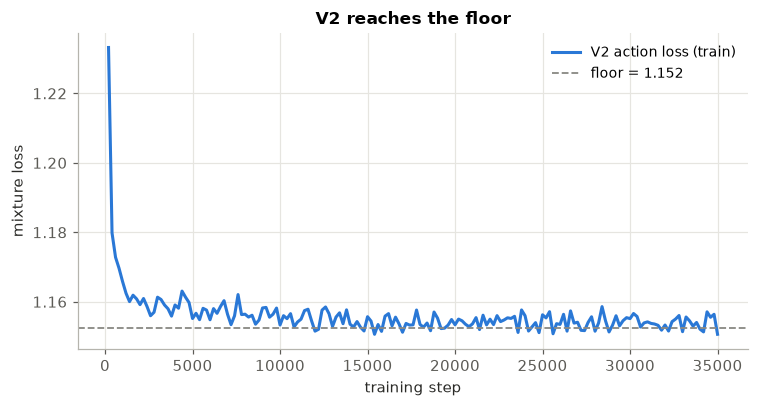

In [3]:
LOG_EVERY = 200
brain = BrainModel().to(DEVICE)
opt = torch.optim.Adam(brain.parameters(), lr=STEP_LR)
S, A = torch.from_numpy(flat["train"]["state"]), torch.from_numpy(flat["train"]["action"])
P, D, E = (torch.from_numpy(flat["train"][k]) for k in ("pick", "drop", "eps"))

curve, running, n, step = [], 0.0, 0, 0
for epoch in range(1, STEP_EPOCHS + 1):
    perm, t0 = torch.randperm(len(A)), time.time()
    for start in range(0, len(A), STEP_BATCH):
        idx = perm[start:start + STEP_BATCH]
        a_logit, p_logit, d_logit = brain(S[idx].to(DEVICE))
        loss_action = mixture_nll(a_logit, A[idx].to(DEVICE), E[idx].to(DEVICE)).mean()
        loss = (loss_action
                + F.binary_cross_entropy_with_logits(p_logit, P[idx].to(DEVICE))
                + F.binary_cross_entropy_with_logits(d_logit, D[idx].to(DEVICE)))
        opt.zero_grad()
        loss.backward()
        opt.step()
        step, running, n = step + 1, running + loss_action.item(), n + 1
        if step % LOG_EVERY == 0:
            curve.append((step, running / n))
            running, n = 0.0, 0
    print(f"epoch {epoch} done in {time.time() - t0:.0f} s")

torch.save(brain.state_dict(), OUT_DIR / "brain_model.pt")
print("saved", OUT_DIR / "brain_model.pt")

train_floor = true_entropy(flat["train"]["state"], flat["train"]["eps"]).mean()
fig, ax = plt.subplots(figsize=(7, 3.8))
if curve:
    steps, losses = zip(*curve)
    ax.plot(steps, losses, color=C["blue"], label="V2 action loss (train)")
ax.axhline(train_floor, color=C["gray"], ls="--", lw=1.2, label=f"floor = {train_floor:.3f}")
ax.set(xlabel="training step", ylabel="mixture loss", title="V2 reaches the floor")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** In the recorded run the epoch-average action loss was 1.158 and then 1.154, essentially on the floor (1.152). V1's loss levelled off around 1.20.

## 3. Did the brain learn the rule?

In [4]:
@torch.no_grad()
def predict(model, f, batch=65536):
    model.eval()
    probs, pick, drop = [], [], []
    for start in range(0, len(f["action"]), batch):
        a_logit, p_logit, d_logit = model(torch.from_numpy(f["state"][start:start + batch]).to(DEVICE))
        probs.append(a_logit.softmax(-1).cpu().numpy())
        pick.append((p_logit > 0).cpu().numpy())
        drop.append((d_logit > 0).cpu().numpy())
    return np.concatenate(probs), np.concatenate(pick), np.concatenate(drop)


f = flat["val"]
probs, pick_pred, drop_pred = predict(brain, f)
s, a, e = f["state"], f["action"], f["eps"]
pred, best, k = probs.argmax(1), best_dir(s), n_ties(s)
clear, see = k == 1, sees_target(s)
spread = probs[k == 4].max(1) - probs[k == 4].min(1)
nll = -np.log((1 - e) * probs[np.arange(len(a)), a] + e / N_ACTIONS + 1e-12)

print(f"agrees with rule, clear rows: {(pred[clear] == best[clear]).mean():.4f}   (want 1)")
print(f"   target-driven rows:        {(pred[clear & see] == best[clear & see]).mean():.4f}")
print(f"   smell-driven rows:         {(pred[clear & ~see] == best[clear & ~see]).mean():.4f}")
print(f"confidence on clear rows:     {probs[clear].max(1).mean():.4f}   (want close to 1)")
print(f"uniform when no signal:       max spread {spread.max():.6f}   (want 0)")
print(f"action loss above floor:      {nll.mean() - true_entropy(s, e).mean():.4f}   (want 0)")
for name, true, guess in [("pick", f["pick"] > 0.5, pick_pred), ("drop", f["drop"] > 0.5, drop_pred)]:
    tp = (true & guess).sum()
    print(f"{name}: precision {tp / max(guess.sum(), 1):.3f}  recall {tp / max(true.sum(), 1):.3f}")

agrees with rule, clear rows: 1.0000   (want 1)
   target-driven rows:        0.9995
   smell-driven rows:         1.0000
confidence on clear rows:     0.9984   (want close to 1)
uniform when no signal:       max spread 0.000000   (want 0)
action loss above floor:      0.0011   (want 0)
pick: precision 1.000  recall 1.000
drop: precision 1.000  recall 1.000


**Analysis.** Recorded: agreement 1.0000 (target-driven 0.9995, smell-driven 1.0000), confidence 0.9984, no-signal spread 0.000000, loss above floor 0.0011, pick and drop 1.000. The shared per-direction scorer makes the no-signal case exactly uniform by construction, and the mixture loss lets the brain be fully confident because the random moves no longer count against it.

## 4. V1 vs V2 on the hardest steps (nearly tied smells)

            V2
0-0.01     1.0
0.01-0.03  1.0
0.03-0.1   1.0
0.1-0.3    1.0
0.3+       1.0


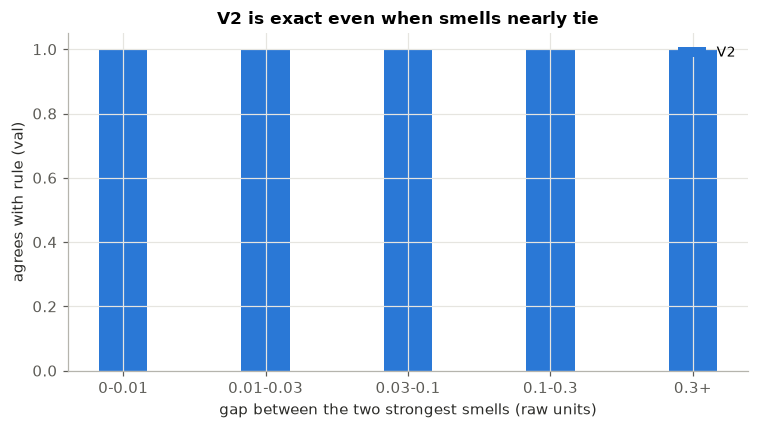

In [5]:
raw_val = np.concatenate([r["state"].reshape(-1, 19) for r in load_split("val")])
m = clear & ~see                                                     # smell-driven clear rows
smell_raw = np.where((raw_val[:, CARRYING] > 0.5)[:, None], raw_val[:, SMELL_HOME], raw_val[:, SMELL_FOOD])[m]
top2 = np.sort(smell_raw, axis=1)[:, -2:]
bins = [0, 0.01, 0.03, 0.1, 0.3, 1.01]
labels = ["0-0.01", "0.01-0.03", "0.03-0.1", "0.1-0.3", "0.3+"]
idx = np.digitize(top2[:, 1] - top2[:, 0], bins) - 1
ok = pred[m] == best[m]
v2 = pd.Series({lab: ok[idx == i].mean() for i, lab in enumerate(labels) if (idx == i).any()}, name="V2")
del raw_val, smell_raw

table = v2.to_frame()
v1_path = OUT_DIR / "v1_margin_agreement.csv"
if v1_path.exists():
    table["V1"] = pd.read_csv(v1_path).set_index("margin")["agree"]
print(table.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(table))
cols = [c for c in ["V1", "V2"] if c in table]
for i, col in enumerate(cols):
    ax.bar(x + (i - (len(cols) - 1) / 2) * 0.36, table[col], width=0.34,
           color=C["orange"] if col == "V1" else C["blue"], label=col)
ax.set_xticks(x, table.index)
ax.set(xlabel="gap between the two strongest smells (raw units)", ylabel="agrees with rule (val)",
       ylim=(0, 1.05), title="V2 is exact even when smells nearly tie")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded V2 agreement is 1.000 in every bin, including the 202,754 val rows with a smell gap below 0.01 where V1 managed 0.626. Normalizing each smell block to 0..1 turns tiny raw gaps into clear ones, and the mixture loss lets the brain commit to them.

## 5. In the simulator: does the learned brain make the same decisions?

In [6]:
import copy, types

sim_mod, Simulation, Config = import_sim()
original_decide = sim_mod.decide            # the real brain
cpu_brain = copy.deepcopy(brain).cpu().eval()


@torch.no_grad()
def learned_decide(ant, local, rng, cfg):
    """Drop-in replacement for the real decide(): learned brain + the same eps-greedy noise."""
    x = torch.from_numpy(normalize(ant.obs[None]))                   # SAME normalize as training
    a_logit, p_logit, d_logit = cpu_brain(x)
    if rng.random() < cfg.epsilon:
        d = int(rng.integers(N_ACTIONS))                               # random move
    else:
        prob = a_logit.softmax(-1)[0].numpy().astype(np.float64)
        d = int(rng.choice(N_ACTIONS, p=prob / prob.sum()))            # brain move (sampling splits ties)
    action = np.zeros(N_ACTIONS, dtype=np.float32)
    action[d] = 1.0
    return types.SimpleNamespace(action=action, pick=bool(p_logit.item() > 0),
                                 drop=bool(d_logit.item() > 0), mode="learned")


CHECK = {}


@torch.no_grad()
def compare_decide(ant, local, rng, cfg):
    """Ants follow the REAL brain; on every decision we also ask the learned brain and compare odds."""
    s = np.asarray(ant.obs, dtype=np.float32)[None]
    true = true_probs(s, cfg.epsilon)[0]
    a_logit, p_logit, d_logit = cpu_brain(torch.from_numpy(normalize(s)))
    learned = (1 - cfg.epsilon) * a_logit.softmax(-1)[0].numpy() + cfg.epsilon / N_ACTIONS
    CHECK["tv"] += 0.5 * np.abs(true - learned).sum()                 # 0 = identical odds
    CHECK["pick_ok"] += bool(p_logit.item() > 0) == bool(local.on_food and not ant.carrying)
    CHECK["drop_ok"] += bool(d_logit.item() > 0) == bool(local.at_home and ant.carrying)
    CHECK["n"] += 1
    return original_decide(ant, local, rng, cfg)


torch.set_num_threads(1)                      # one-row model calls are faster single-threaded
for eps in [0.1, 0.5]:
    CHECK.update(tv=0.0, pick_ok=0, drop_ok=0, n=0)
    run_sim(eps, 0, compare_decide, T=min(500, SIM_STEPS))
    n = CHECK["n"]
    print(f"eps {eps}: avg odds difference {CHECK['tv'] / n:.5f}   "
          f"pick agrees {CHECK['pick_ok'] / n:.4f}   drop agrees {CHECK['drop_ok'] / n:.4f}")

eps 0.1: avg odds difference 0.00077   pick agrees 1.0000   drop agrees 1.0000
eps 0.5: avg odds difference 0.00010   pick agrees 1.0000   drop agrees 1.0000


**Analysis.** Recorded average odds difference (total variation): 0.00077 at eps 0.1 and 0.00010 at eps 0.5, with pick and drop agreeing on every decision. On the states the colony actually visits, the learned brain decides like the real one.

## 6. In the simulator: food delivered, real vs learned brain

In [7]:
rows = []
for eps in [0.1, 0.3, 0.5]:
    for seed in SIM_SEEDS:
        rows.append(dict(eps=eps, seed=seed,
                         real=run_sim(eps, seed, original_decide),
                         learned=run_sim(eps, seed, learned_decide)))
sim_results = pd.DataFrame(rows)
print(sim_results.groupby("eps")[["real", "learned"]].agg(["mean", "std"]).round(1))

diff = sim_results.learned - sim_results.real                    # paired by (eps, seed)
t_paired = diff.mean() / (diff.std(ddof=1) / np.sqrt(len(diff))) if diff.std(ddof=1) > 0 else np.nan
print(f"\npaired difference over {len(diff)} runs: {diff.mean():.1f} items (t = {t_paired:.2f})")

      real       learned      
      mean   std    mean   std
eps                           
0.1  369.4  63.2   320.5  64.7
0.3  356.3  84.6   323.6  42.1
0.5  335.1  63.9   324.6  67.3

paired difference over 30 runs: -30.7 items (t = -2.02)


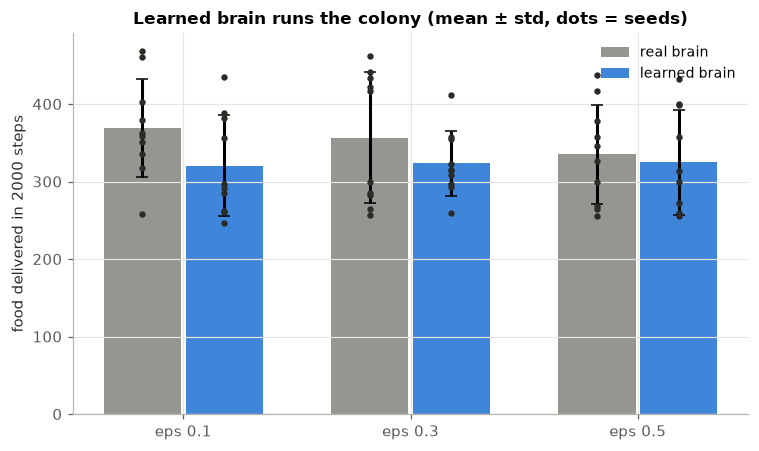

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(3)
for i, (col, color) in enumerate([("real", C["gray"]), ("learned", C["blue"])]):
    g = sim_results.groupby("eps")[col]
    ax.bar(x + (i - 0.5) * 0.36, g.mean(), width=0.34, yerr=g.std(), capsize=4,
           color=color, alpha=0.9, label=f"{col} brain")
    for j, eps in enumerate([0.1, 0.3, 0.5]):              # individual seeds
        vals = sim_results[sim_results.eps == eps][col]
        ax.scatter(np.full(len(vals), j + (i - 0.5) * 0.36), vals, s=10, color=C["ink"], zorder=3)
ax.set_xticks(x, ["eps 0.1", "eps 0.3", "eps 0.5"])
ax.set(ylabel=f"food delivered in {SIM_STEPS} steps", title="Learned brain runs the colony (mean ± std, dots = seeds)")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded (2000 steps, 10 seeds): real 369.4 ± 63.2, 356.3 ± 84.6, 335.1 ± 63.9 vs learned 320.5 ± 64.7, 323.6 ± 42.1, 324.6 ± 67.3 at eps 0.1 / 0.3 / 0.5. Seed-to-seed spread (about 60 items) is larger than the gap at each eps, but pooled over all 30 paired runs the learned brain delivers about 31 fewer items (t about -2.0), so the gap is probably real but small.

## 7. Where does the food gap come from?

In [9]:
def real_but_relabeled(ant, local, rng, cfg):
    """The REAL brain's decision, returned the way learned_decide returns it."""
    dec = original_decide(ant, local, rng, cfg)
    return types.SimpleNamespace(action=dec.action, pick=dec.pick, drop=dec.drop, mode="learned")


@torch.no_grad()
def learned_top_choice(ant, local, rng, cfg):
    """Learned brain, but takes its top choice (random among near-ties) instead of sampling."""
    a_logit, p_logit, d_logit = cpu_brain(torch.from_numpy(normalize(ant.obs[None])))
    if rng.random() < cfg.epsilon:
        d = int(rng.integers(N_ACTIONS))
    else:
        prob = a_logit.softmax(-1)[0].numpy()
        d = int(rng.choice(np.flatnonzero(prob >= prob.max() - 1e-3)))
    action = np.zeros(N_ACTIONS, dtype=np.float32)
    action[d] = 1.0
    return types.SimpleNamespace(action=action, pick=bool(p_logit.item() > 0),
                                 drop=bool(d_logit.item() > 0), mode="learned")


brains = {"real": original_decide, "real, relabeled": real_but_relabeled,
          "learned (samples)": learned_decide, "learned (top choice)": learned_top_choice}
gap_check = pd.DataFrame([{name: run_sim(0.1, seed, fn) for name, fn in brains.items()} for seed in SIM_SEEDS])
print("eps 0.1, food delivered:")
print(gap_check.agg(["mean", "std"]).round(1))
torch.set_num_threads(max(1, os.cpu_count() or 1))

eps 0.1, food delivered:
       real  real, relabeled  learned (samples)  learned (top choice)
mean  369.4            369.4              320.5                 315.3
std    63.2             63.2               64.7                  48.3


**Analysis.** Recorded at eps 0.1: real 369.4, real relabeled 369.4 (identical, so the `mode` label does not matter), learned sampling 320.5, learned top choice 315.3. Both learned variants are lower, while section 5 shows their odds match the real brain to within 0.001. What the two learned variants share is a different sequence of random-number calls, which changes every later trajectory; with seed spread of about 60 items this can shift means by tens of items. Not resolved here; a cleaner test would replay identical random draws through both brains.